# Neural and sequential models: NeuMF and SASRec

In [1]:
import json, sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from recsys.config import RESULTS_DIR, COLD_REVEAL
from recsys.data import load

ORDER = ['popularity', 'knn', 'als', 'svd', 'bpr', 'ncf', 'sasrec', 'content']   # models in the order of the comparison
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, GRAY, ORANGE = "#2a6fb0", "#8a8f98", "#d9822b"
ROOT = Path.cwd().parent
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"eda_{name}.png", dpi=150)
    plt.show()

data = load()
cold = load(ROOT / "data" / "processed_coldstart")
log = data.meta["preprocess_log"]
train, val, test, users, items = data.train, data.val, data.test, data.users, data.items
allx = pd.concat([train, val, test], ignore_index=True)
allx["year"] = pd.to_datetime(allx["timestamp"], unit="ms").dt.year
print(data.meta["dataset"], "| data version", data.data_version, "| cold-start version", cold.data_version)

Amazon Reviews 2023, Video Games (McAuley Lab, UCSD) | data version 4fe78b90381a | cold-start version 6943ffc82a19


In [2]:
from recsys.report import sweep_table

def curve_plot(model):
    r = json.load(open(RESULTS_DIR / f"{model}_final.json"))
    if not r.get("curve"):
        print(f"{model} has no iterative training curve")
        return
    c = pd.DataFrame(r["curve"])
    xcol = "epoch" if "epoch" in c else "iteration"
    ycols = [k for k in c.columns if k != xcol]
    fig, axes = plt.subplots(1, len(ycols), figsize=(4.6 * len(ycols), 3.4))
    for ax, y in zip(np.atleast_1d(axes), ycols):
        ax.plot(c[xcol], c[y], color=BLUE, lw=2, marker="o", ms=3)
        if r.get("best_epoch"):
            ax.axvline(r["best_epoch"], color=ORANGE, ls="--", label=f"best epoch {r['best_epoch']}")
            ax.legend(frameon=False)
        ax.set(xlabel=xcol, ylabel=y, title=f"{model}: {y}")
    plt.tight_layout(); plt.savefig(FIG / f"curve_{model}.png", dpi=150); plt.show()

## ncf
Neural collaborative filtering, NeuMF (He et al., 2017). A GMF tower (elementwise product of embeddings) and an MLP tower (concatenated embeddings through hidden layers) are joined by one linear layer. Trained with sampled negatives and binary cross-entropy.

In [3]:
sw = sweep_table("ncf")
print("ncf: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

ncf: 12 runs, winner on validation: ncf_final


,run,cfg_factors,cfg_mlp_factors,cfg_layers,cfg_lr,cfg_neg,cfg_batch_size,cfg_epochs,cfg_patience,cfg_reg,cfg_dropout,val_ndcg@10,test_recall@10,fit_seconds,selected
0,ncf_final,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0030,0.2,0.024887,0.037705,65.78,True
1,ncf_dropout0.2_patience5_epochs40_reg0.003,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0030,0.2,0.024865,0.037599,134.10,False
2,ncf_dropout0.2_patience5_epochs40_reg0.005,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0050,0.2,0.024678,0.037483,83.21,False
3,ncf_reg0.003_patience5_epochs40_dropout0.5,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0030,0.5,0.024311,0.035331,125.25,False
4,ncf_reg0.001_patience5_epochs40_dropout0.5,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0010,0.5,0.022638,0.032144,143.09,False
5,ncf_dropout0.2_patience5_epochs40_reg0.001,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0010,0.2,0.022080,0.031204,212.16,False
6,ncf_dropout0.2_patience5_epochs40_reg0.0003,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0003,0.2,0.019479,0.027690,199.61,False
7,ncf_reg0.003_dropout0.2_patience5_epochs40_lr0...,32,32,"[64, 32, 16]",0.003,4,4096,40,5,0.0030,0.2,0.018886,0.029273,95.80,False
8,ncf_dropout0.2_patience5_epochs40_reg0.01,32,32,"[64, 32, 16]",0.001,4,4096,40,5,0.0100,0.2,0.018376,0.031278,189.95,False
9,ncf_mlp_factors16_reg0.001_dropout0.2_patience...,16,16,"[64, 32, 16]",0.001,4,4096,40,5,0.0010,0.2,0.017070,0.026076,75.58,False


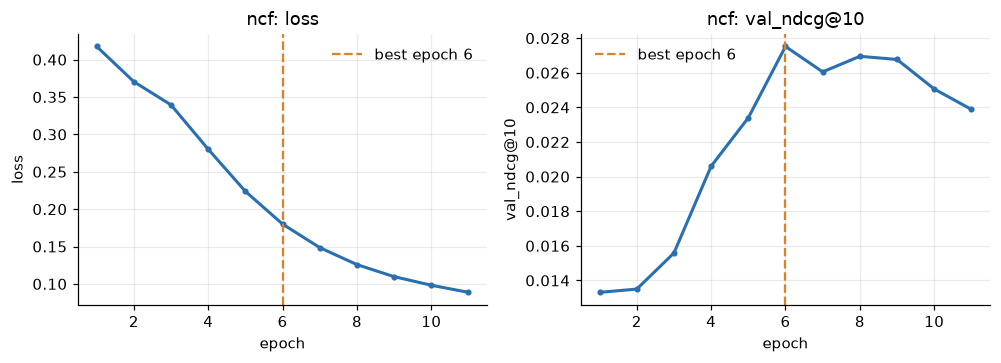

In [4]:
curve_plot("ncf")

The unregularised network memorises the training data: over 10 epochs its training loss fell from 0.41 to 0.06 while validation NDCG@10 stayed near 0.0169 and test Recall@10 was only 0.0250. An L2 penalty on the embeddings and dropout in the MLP helped substantially, though it stays well below the matrix-factorization models: the best setting (reg 0.003, dropout 0.2) reaches test Recall@10 0.0377 and NDCG@10 0.0197. Scoring all items takes 0.62 ms per user, about 13 times KNN, because every user-item pair goes through the MLP; the network has 7.7 million parameters.

## sasrec
Self-attentive sequential recommendation (Kang and McAuley, 2018): a transformer over the user's chronological purchases that predicts the next item. It scores users from the history it is given, so it handles new users with a few revealed purchases.

In [5]:
sw = sweep_table("sasrec")
print("sasrec: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

sasrec: 19 runs, winner on validation: sasrec_blocks1_dropout0.5_hidden128


,run,cfg_max_len,cfg_hidden,cfg_blocks,cfg_heads,cfg_dropout,cfg_lr,cfg_batch_size,cfg_epochs,cfg_patience,val_ndcg@10,test_recall@10,fit_seconds,selected
0,sasrec_blocks1_dropout0.5_hidden128,20,128,1,2,0.5,0.0010,256,50,5,0.037131,0.061807,107.77,True
1,sasrec_final,20,128,1,2,0.5,0.0010,256,50,5,0.036574,0.063211,99.49,False
2,sasrec_blocks1_dropout0.5_max_len30,30,64,1,2,0.5,0.0010,256,50,5,0.036483,0.061871,111.06,False
3,sasrec_blocks1_dropout0.5,20,64,1,2,0.5,0.0010,256,50,5,0.035710,0.060752,208.56,False
4,sasrec_blocks1_dropout0.6,20,64,1,2,0.6,0.0010,256,50,5,0.035623,0.061902,187.14,False
5,sasrec_blocks1_dropout0.4,20,64,1,2,0.4,0.0010,256,50,5,0.035348,0.062124,135.52,False
6,sasrec_blocks1_dropout0.5_max_len50,50,64,1,2,0.5,0.0010,256,50,5,0.034458,0.060573,116.96,False
7,sasrec_dropout0.4,20,64,2,2,0.4,0.0010,256,50,5,0.034092,0.058473,170.73,False
8,sasrec_blocks1_dropout0.5_hidden32,20,32,1,2,0.5,0.0010,256,50,5,0.032999,0.058051,89.29,False
9,sasrec_blocks1,20,64,1,2,0.2,0.0010,256,50,5,0.032719,0.056457,224.51,False


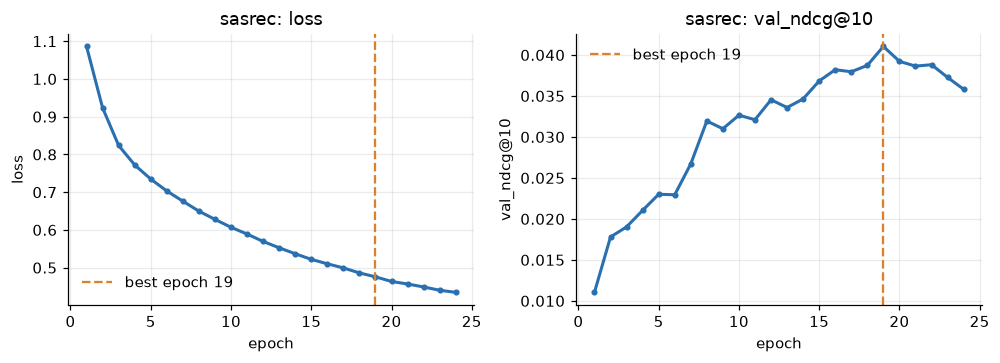

In [6]:
curve_plot("sasrec")

On this small dataset fewer blocks were better at equal dropout 0.2 (validation NDCG@10 0.0327 with one block, 0.0320 with two, 0.0284 with three) and more dropout helped (two blocks: 0.0297 with dropout 0.1, 0.0320 with 0.2, 0.0341 with 0.4). The final model (one block, hidden size 128, dropout 0.5, last 20 purchases) has test Recall@10 0.0632 and NDCG@10 0.0335. Its validation and test NDCG@10 (0.0366 and 0.0335) are close, consistent with it reading the history it is given, which at test time includes the validation purchase. Fit 99 s, scoring 0.016 ms per user, 3.4 million parameters.

## Final runs against the popularity baseline

In [7]:

rows = []
for name in ["popularity"] + ['ncf', 'sasrec']:
    r = json.load(open(RESULTS_DIR / f"{name}_final.json"))
    t, c = r["test"], r["cost"]
    rows.append({"model": name, "recall@10": t["recall@10"], "ndcg@10": t["ndcg@10"], "mrr": t["mrr"], "rmse": t["rmse"],
                 "coverage@10": t["coverage@10"], "fit_seconds": c["fit_seconds"], "score_ms_per_user": c["score_ms_per_user"]})
pd.DataFrame(rows).round(4)


,model,recall@10,ndcg@10,mrr,rmse,coverage@10,fit_seconds,score_ms_per_user
0,popularity,0.0249,0.0126,0.0120,1.25,0.0008,0.00,0.0013
1,ncf,0.0377,0.0197,0.0187,NaN,0.2340,65.78,0.6201
2,sasrec,0.0632,0.0335,0.0311,NaN,0.2176,99.49,0.0162
